# Reclassify the Complete Nairobi GSV Dataset Using the Aligned 80 m Cell Mapping (v2)

This notebook supersedes the earlier version.

It rebuilds the GSV manifest from the complete, unclassified source folder and uses:

```text
F:\Master Research Thesis\Code\Mapping_Generation\outputs\
latest_aligned_v2\cell_index_mapping_v2.csv
```

as the **single authoritative source** for both split and label.

Key rules:

1. The original 306/102/102 patch split is retained.
2. Each image is located on the S2-derived aligned 80 m grid.
3. Each image inherits the split and label of its 80 m cell.
4. The 80 m raster validates the cell mapping; it does not independently label each GSV point.
5. `reference_label = -1`, locations outside selected patches, and parse failures are assigned to `out`.
6. K=7 slot ordering is deterministic.
7. A complete wide slot table is generated for all 130,560 model positions.
8. Physical copying remains disabled by default with `DRY_RUN = True`.

In [1]:
# =========================
# 1. IMPORTS AND PATH SETTINGS
# =========================

from pathlib import Path
from datetime import datetime
import hashlib
import json
import math
import platform
import re
import shutil
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.collections import PatchCollection
from matplotlib.lines import Line2D
from IPython.display import display
from affine import Affine
from pyproj import Transformer
import rasterio

plt.style.use("default")

CODE_ROOT = Path(r"F:\Master Research Thesis\Code")
MAPPING_ROOT = CODE_ROOT / "Mapping_Generation"

S2_MAPPING_DIR = (
    MAPPING_ROOT
    / "outputs"
    / "latest_aligned_v2"
)

PATCH_MAPPING_FILE = (
    S2_MAPPING_DIR
    / "patch_index_mapping.csv"
)

CELL_MAPPING_FILE = (
    S2_MAPPING_DIR
    / "cell_index_mapping_v2.csv"
)

SATELLITE_DIR = CODE_ROOT / "Satellite_branch"

S2_RASTER_FILE = (
    SATELLITE_DIR
    / "Nrb_sentinel2_extent3857.tif"
)

LABEL_RASTER_FILE = (
    MAPPING_ROOT
    / "reference_alignment_v2"
    / "Nrb_reference_binary_aligned_to_s2_80m.tif"
)

FULL_GSV_SOURCE_DIR = Path(
    r"H:\Research Thesis\Dataset\Nrb_GSV\Nrb_images"
)

TARGET_ROOT = Path(
    r"H:\Research Thesis\Dataset\Nrb_GSV"
    r"\Nrb_images_verified_by_aligned_cell_v2"
)

RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")

OUT_DIR = (
    MAPPING_ROOT
    / "outputs"
    / f"full_gsv_aligned_v2_run_{RUN_ID}"
)

FIG_DIR = OUT_DIR / "figures"

LATEST_GSV_DIR = (
    MAPPING_ROOT
    / "outputs"
    / "latest_full_gsv_aligned_v2"
)

OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

required_paths = [
    PATCH_MAPPING_FILE,
    CELL_MAPPING_FILE,
    S2_RASTER_FILE,
    LABEL_RASTER_FILE,
    FULL_GSV_SOURCE_DIR,
]

for path in required_paths:
    print(path, "exists:", path.exists())

missing_paths = [
    path
    for path in required_paths
    if not path.exists()
]

if missing_paths:
    raise FileNotFoundError(
        "Missing required paths:\n"
        + "\n".join(str(path) for path in missing_paths)
    )

print("OUT_DIR:", OUT_DIR)
print("LATEST_GSV_DIR:", LATEST_GSV_DIR)
print("TARGET_ROOT:", TARGET_ROOT)

F:\Master Research Thesis\Code\Mapping_Generation\outputs\latest_aligned_v2\patch_index_mapping.csv exists: True
F:\Master Research Thesis\Code\Mapping_Generation\outputs\latest_aligned_v2\cell_index_mapping_v2.csv exists: True
F:\Master Research Thesis\Code\Satellite_branch\Nrb_sentinel2_extent3857.tif exists: True
F:\Master Research Thesis\Code\Mapping_Generation\reference_alignment_v2\Nrb_reference_binary_aligned_to_s2_80m.tif exists: True
H:\Research Thesis\Dataset\Nrb_GSV\Nrb_images exists: True
OUT_DIR: F:\Master Research Thesis\Code\Mapping_Generation\outputs\full_gsv_aligned_v2_run_20260731_164912
LATEST_GSV_DIR: F:\Master Research Thesis\Code\Mapping_Generation\outputs\latest_full_gsv_aligned_v2
TARGET_ROOT: H:\Research Thesis\Dataset\Nrb_GSV\Nrb_images_verified_by_aligned_cell_v2


In [2]:
# =========================
# 2. CONFIGURATION
# =========================

VALID_IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

PATCH_SIZE_M = 1280.0
CELL_SIZE_M = 80.0
CELLS_PER_PATCH_SIDE = 16
CELLS_PER_PATCH = 256
K = 7

DRY_RUN = True
ALLOW_NONEMPTY_TARGET = False

COORDINATE_TOLERANCE_M = 1e-6
CELL_EDGE_WIDTH = 0.002

SPLIT_ORDER = ["train", "val", "test", "out"]
LABEL_ORDER = ["non_slum", "slum", "out"]

SPLIT_COLORS = {
    "train": "#1f77b4",
    "val": "#ff7f0e",
    "test": "#2ca02c",
}

EXPECTED_PATCH_COUNTS = {
    "train": 306,
    "val": 102,
    "test": 102,
}

config = {
    "run_id": RUN_ID,
    "full_gsv_source_dir": str(FULL_GSV_SOURCE_DIR),
    "target_root": str(TARGET_ROOT),
    "patch_mapping_file": str(PATCH_MAPPING_FILE),
    "cell_mapping_file": str(CELL_MAPPING_FILE),
    "s2_raster_file": str(S2_RASTER_FILE),
    "label_raster_file": str(LABEL_RASTER_FILE),
    "patch_size_m": PATCH_SIZE_M,
    "cell_size_m": CELL_SIZE_M,
    "K": K,
    "dry_run": DRY_RUN,
    "classification_rule": (
        "Each image is located on the S2-derived aligned 80 m grid. "
        "Its split and final label are inherited from "
        "cell_index_mapping_v2.csv. The aligned 80 m raster is used "
        "only to validate the cell mapping; it is not sampled as an "
        "independent point-level label source."
    ),
}

with open(
    OUT_DIR / "full_gsv_reclassification_config_v2.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(config, file, indent=2, ensure_ascii=False)

print("Configuration saved.")

Configuration saved.


## Module 3 — Load and validate the aligned-v2 S2 mapping

This module validates the spatial framework before any GSV image is read:

- 510 selected patches and the original 306/102/102 split;
- 256 model positions per patch;
- exact row/global-cell index formulas;
- `reference_label`, `label`, and `valid_cell` consistency;
- exact S2-derived 80 m transform;
- exact agreement between every cell label and the aligned 80 m raster.

In [3]:
# =========================
# 3. LOAD AND VALIDATE ALIGNED-V2 S2 MAPPINGS
# =========================

def coerce_boolean_series(series, column_name):
    if pd.api.types.is_bool_dtype(series):
        return series.astype(bool)

    normalized = (
        series.astype(str)
        .str.strip()
        .str.lower()
    )

    mapping = {
        "true": True,
        "false": False,
        "1": True,
        "0": False,
    }

    unexpected = set(normalized.unique()) - set(mapping)

    if unexpected:
        raise ValueError(
            f"Unexpected Boolean values in {column_name}: "
            f"{sorted(unexpected)}"
        )

    return normalized.map(mapping).astype(bool)


patch_df = pd.read_csv(PATCH_MAPPING_FILE)
cell_df = pd.read_csv(CELL_MAPPING_FILE)

required_patch_columns = {
    "split", "patch_order", "original_patch_index",
    "patch_row", "patch_col", "xmin", "ymin", "xmax", "ymax"
}

required_cell_columns = {
    "split", "patch_order", "original_patch_index",
    "patch_row", "patch_col", "cell_row", "cell_col",
    "global_cell_row", "global_cell_col",
    "row_index_in_split", "reference_label", "label",
    "valid_cell", "is_padding_or_nodata",
    "informal_fraction", "valid_10m_pixel_count",
    "valid_coverage_fraction",
    "xmin", "ymin", "xmax", "ymax"
}

missing_patch_columns = required_patch_columns - set(patch_df.columns)
missing_cell_columns = required_cell_columns - set(cell_df.columns)

if missing_patch_columns:
    raise ValueError(f"Missing patch columns: {sorted(missing_patch_columns)}")

if missing_cell_columns:
    raise ValueError(f"Missing cell columns: {sorted(missing_cell_columns)}")

for column in [
    "patch_order", "original_patch_index", "patch_row", "patch_col"
]:
    patch_df[column] = patch_df[column].astype(int)

for column in [
    "patch_order", "original_patch_index", "patch_row", "patch_col",
    "cell_row", "cell_col", "global_cell_row", "global_cell_col",
    "row_index_in_split", "reference_label", "label",
    "valid_10m_pixel_count"
]:
    cell_df[column] = cell_df[column].astype(int)

cell_df["valid_cell"] = coerce_boolean_series(
    cell_df["valid_cell"],
    "valid_cell",
)

cell_df["is_padding_or_nodata"] = coerce_boolean_series(
    cell_df["is_padding_or_nodata"],
    "is_padding_or_nodata",
)

for split, expected_count in EXPECTED_PATCH_COUNTS.items():
    actual_count = int((patch_df["split"] == split).sum())

    if actual_count != expected_count:
        raise ValueError(
            f"{split}: expected {expected_count} patches, "
            f"found {actual_count}."
        )

if len(patch_df) != 510:
    raise ValueError(f"Expected 510 patches, found {len(patch_df)}.")

if len(cell_df) != 510 * CELLS_PER_PATCH:
    raise ValueError(
        f"Expected 130,560 model positions, found {len(cell_df)}."
    )

if patch_df.duplicated(["patch_row", "patch_col"]).any():
    raise ValueError("Duplicate patch locations found.")

if cell_df.duplicated(
    ["global_cell_row", "global_cell_col"]
).any():
    raise ValueError("Duplicate global cell locations found.")

if cell_df.duplicated(["split", "row_index_in_split"]).any():
    raise ValueError("Duplicate split/row_index_in_split values found.")

cells_per_patch = cell_df.groupby(["split", "patch_order"]).size()

if not (cells_per_patch == CELLS_PER_PATCH).all():
    raise ValueError("Some patches do not contain exactly 256 cells.")

if not np.array_equal(
    cell_df["reference_label"].to_numpy(),
    cell_df["label"].to_numpy(),
):
    raise ValueError("reference_label and label are not identical.")

expected_valid_cell = cell_df["reference_label"].isin([0, 1])

if not np.array_equal(
    expected_valid_cell.to_numpy(),
    cell_df["valid_cell"].to_numpy(),
):
    raise ValueError("valid_cell is inconsistent with reference_label.")

if not np.array_equal(
    (~expected_valid_cell).to_numpy(),
    cell_df["is_padding_or_nodata"].to_numpy(),
):
    raise ValueError(
        "is_padding_or_nodata is inconsistent with reference_label."
    )

expected_global_row = (
    cell_df["patch_row"] * CELLS_PER_PATCH_SIDE
    + cell_df["cell_row"]
)

expected_global_col = (
    cell_df["patch_col"] * CELLS_PER_PATCH_SIDE
    + cell_df["cell_col"]
)

expected_row_index = (
    cell_df["patch_order"] * CELLS_PER_PATCH
    + cell_df["cell_row"] * CELLS_PER_PATCH_SIDE
    + cell_df["cell_col"]
)

if not np.array_equal(
    expected_global_row.to_numpy(),
    cell_df["global_cell_row"].to_numpy(),
):
    raise ValueError("global_cell_row formula mismatch.")

if not np.array_equal(
    expected_global_col.to_numpy(),
    cell_df["global_cell_col"].to_numpy(),
):
    raise ValueError("global_cell_col formula mismatch.")

if not np.array_equal(
    expected_row_index.to_numpy(),
    cell_df["row_index_in_split"].to_numpy(),
):
    raise ValueError("row_index_in_split formula mismatch.")

for split in ["train", "val", "test"]:
    split_rows = np.sort(
        cell_df.loc[
            cell_df["split"] == split,
            "row_index_in_split",
        ].to_numpy(dtype=int)
    )

    if not np.array_equal(
        split_rows,
        np.arange(len(split_rows), dtype=int),
    ):
        raise ValueError(
            f"{split}: row_index_in_split is not contiguous."
        )

with rasterio.open(S2_RASTER_FILE) as s2_source:
    s2_height = s2_source.height
    s2_width = s2_source.width
    s2_transform = s2_source.transform
    s2_bounds = s2_source.bounds
    s2_crs = s2_source.crs

with rasterio.open(LABEL_RASTER_FILE) as label_source:
    label_array = label_source.read(1).astype(np.int8)
    label_transform = label_source.transform
    label_crs = label_source.crs
    label_nodata = label_source.nodata

if s2_crs is None or label_crs is None:
    raise ValueError("S2 or aligned reference has no CRS.")

if s2_crs != label_crs:
    raise ValueError("S2 and aligned reference CRS values differ.")

if s2_crs.to_epsg() != 3857:
    raise ValueError(f"Expected EPSG:3857, found {s2_crs}.")

expected_80m_transform = s2_transform * Affine.scale(8, 8)

if not np.allclose(
    tuple(label_transform)[:6],
    tuple(expected_80m_transform)[:6],
    atol=1e-8,
):
    raise ValueError(
        "Aligned 80 m reference transform does not match "
        "the S2-derived 80 m transform."
    )

expected_label_shape = (s2_height // 8, s2_width // 8)

if label_array.shape != expected_label_shape:
    raise ValueError(
        f"Expected label shape {expected_label_shape}, "
        f"found {label_array.shape}."
    )

unexpected_values = set(np.unique(label_array).tolist()) - {-1, 0, 1}

if unexpected_values:
    raise ValueError(
        f"Unexpected aligned-reference values: {sorted(unexpected_values)}"
    )

ORIGIN_X = float(s2_transform.c)
ORIGIN_Y = float(s2_transform.f)

expected_xmin = ORIGIN_X + cell_df["global_cell_col"] * CELL_SIZE_M
expected_xmax = expected_xmin + CELL_SIZE_M
expected_ymax = ORIGIN_Y - cell_df["global_cell_row"] * CELL_SIZE_M
expected_ymin = expected_ymax - CELL_SIZE_M

for actual, expected, name in [
    (cell_df["xmin"], expected_xmin, "xmin"),
    (cell_df["xmax"], expected_xmax, "xmax"),
    (cell_df["ymin"], expected_ymin, "ymin"),
    (cell_df["ymax"], expected_ymax, "ymax"),
]:
    if not np.allclose(
        actual.to_numpy(dtype=float),
        expected.to_numpy(dtype=float),
        atol=1e-6,
    ):
        raise ValueError(f"Cell-bound mismatch in {name}.")

global_rows = cell_df["global_cell_row"].to_numpy(dtype=int)
global_cols = cell_df["global_cell_col"].to_numpy(dtype=int)

inside_physical_reference = (
    (global_rows >= 0)
    & (global_rows < label_array.shape[0])
    & (global_cols >= 0)
    & (global_cols < label_array.shape[1])
)

expected_labels_from_raster = np.full(
    len(cell_df),
    -1,
    dtype=np.int8,
)

inside_positions = np.where(inside_physical_reference)[0]

expected_labels_from_raster[inside_positions] = label_array[
    global_rows[inside_positions],
    global_cols[inside_positions],
]

cell_label_matches_raster = (
    expected_labels_from_raster
    == cell_df["reference_label"].to_numpy(dtype=np.int8)
)

cell_raster_validation_df = cell_df[
    [
        "split", "patch_order", "row_index_in_split",
        "global_cell_row", "global_cell_col",
        "reference_label", "valid_cell"
    ]
].copy()

cell_raster_validation_df[
    "inside_physical_reference"
] = inside_physical_reference

cell_raster_validation_df[
    "expected_label_from_raster"
] = expected_labels_from_raster

cell_raster_validation_df[
    "label_matches_raster"
] = cell_label_matches_raster

cell_raster_validation_df.to_csv(
    OUT_DIR / "aligned_v2_cell_to_raster_validation.csv",
    index=False,
)

cell_raster_mismatch_df = cell_raster_validation_df.loc[
    ~cell_raster_validation_df["label_matches_raster"]
].copy()

cell_raster_mismatch_df.to_csv(
    OUT_DIR / "aligned_v2_cell_to_raster_mismatches.csv",
    index=False,
)

if len(cell_raster_mismatch_df) > 0:
    display(cell_raster_mismatch_df.head(20))
    raise RuntimeError(
        f"{len(cell_raster_mismatch_df)} cells do not match "
        "the aligned reference raster."
    )

lookup_columns = [
    "split", "patch_order", "original_patch_index",
    "patch_row", "patch_col", "cell_row", "cell_col",
    "global_cell_row", "global_cell_col",
    "row_index_in_split", "reference_label", "valid_cell",
    "informal_fraction", "valid_10m_pixel_count",
    "valid_coverage_fraction",
    "xmin", "ymin", "xmax", "ymax"
]

cell_lookup = {
    (int(row.global_cell_row), int(row.global_cell_col)): {
        column: getattr(row, column)
        for column in lookup_columns
    }
    for row in cell_df[lookup_columns].itertuples(index=False)
}

print("Verified patches:", len(patch_df))
print("All model positions:", len(cell_df))
print("Valid labelled cells:", int(cell_df["valid_cell"].sum()))
print("Invalid/background/padding:", int((~cell_df["valid_cell"]).sum()))
print("Grid origin:", ORIGIN_X, ORIGIN_Y)
print("Cell-to-raster mismatches:", len(cell_raster_mismatch_df))

display(
    patch_df.groupby("split").size().rename("patches").reset_index()
)

display(
    cell_df.groupby(
        ["split", "reference_label"]
    ).size().rename("cells").reset_index()
)

print("Aligned-v2 mapping validation passed.")

Verified patches: 510
All model positions: 130560
Valid labelled cells: 112600
Invalid/background/padding: 17960
Grid origin: 4081450.0 -129210.0
Cell-to-raster mismatches: 0


,split,patches
0,test,102
1,train,306
2,val,102


,split,reference_label,cells
0,test,-1,3756
1,test,0,20827
2,test,1,1529
3,train,-1,11116
4,train,0,62787
5,train,1,4433
6,val,-1,3088
7,val,0,21566
8,val,1,1458


Aligned-v2 mapping validation passed.


## Module 4 — Helper functions

These functions identify real images, exclude macOS metadata files, parse coordinates,
calculate global 80 m indices, and classify unmatched locations.

In [4]:
# =========================
# 4. HELPER FUNCTIONS
# =========================

transformer = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:3857",
    always_xy=True,
)


def is_real_image(path):
    if not path.is_file():
        return False

    if path.suffix.lower() not in VALID_IMAGE_EXTENSIONS:
        return False

    if path.name.startswith("._") or path.name.startswith("."):
        return False

    if "__MACOSX" in path.parts:
        return False

    return True


def parse_gsv_filename(path):
    """
    Expected filename ending:
        <FID>_<longitude>_<latitude>.<extension>

    rsplit permits underscores inside FID.
    """
    parts = path.stem.rsplit("_", 2)

    if len(parts) != 3:
        raise ValueError(
            f"Filename does not match FID_lon_lat pattern: {path.name}"
        )

    fid, lon_text, lat_text = parts

    if not fid:
        raise ValueError(f"Empty FID: {path.name}")

    lon = float(lon_text)
    lat = float(lat_text)

    if not np.isfinite(lon) or not np.isfinite(lat):
        raise ValueError(f"Non-finite coordinate: {path.name}")

    if not (-180.0 <= lon <= 180.0):
        raise ValueError(f"Invalid longitude: {path.name}")

    if not (-90.0 <= lat <= 90.0):
        raise ValueError(f"Invalid latitude: {path.name}")

    try:
        fid_numeric = int(fid)
    except ValueError:
        fid_numeric = np.nan

    return fid, fid_numeric, lon, lat


def point_to_global_cell_indices(x, y):
    global_cell_col = int(
        math.floor((x - ORIGIN_X) / CELL_SIZE_M)
    )

    global_cell_row = int(
        math.floor((ORIGIN_Y - y) / CELL_SIZE_M)
    )

    return global_cell_row, global_cell_col


def point_inside_cell(x, y, cell_record):
    tolerance = COORDINATE_TOLERANCE_M

    return (
        float(cell_record["xmin"]) - tolerance
        <= x
        < float(cell_record["xmax"]) + tolerance
        and float(cell_record["ymin"]) - tolerance
        < y
        <= float(cell_record["ymax"]) + tolerance
    )


def inside_original_s2_raster(x, y):
    return (
        s2_bounds.left <= x < s2_bounds.right
        and s2_bounds.bottom < y <= s2_bounds.top
    )


print("Helper functions loaded.")

Helper functions loaded.


## Module 5 — Scan the complete unclassified source

This module creates a clean inventory of all real images and separately records hidden or AppleDouble files. It does not classify any image.

In [5]:
# =========================
# 5. SCAN COMPLETE UNCLASSIFIED GSV SOURCE
# =========================

all_image_like_files = [
    path
    for path in FULL_GSV_SOURCE_DIR.rglob("*")
    if path.is_file()
    and path.suffix.lower() in VALID_IMAGE_EXTENSIONS
]

all_image_like_files = sorted(
    all_image_like_files,
    key=lambda path: str(path).lower(),
)

real_image_paths = []
ignored_rows = []

for path in all_image_like_files:
    if path.name.startswith("._"):
        ignored_rows.append({
            "path": str(path),
            "reason": "AppleDouble_metadata",
        })
        continue

    if path.name.startswith("."):
        ignored_rows.append({
            "path": str(path),
            "reason": "hidden_file",
        })
        continue

    if "__MACOSX" in path.parts:
        ignored_rows.append({
            "path": str(path),
            "reason": "__MACOSX_folder",
        })
        continue

    real_image_paths.append(path)

ignored_df = pd.DataFrame(
    ignored_rows,
    columns=["path", "reason"],
)

source_inventory_df = pd.DataFrame({
    "image_uid": [
        hashlib.sha1(
            str(path.relative_to(FULL_GSV_SOURCE_DIR))
            .replace("\\", "/")
            .lower()
            .encode("utf-8")
        ).hexdigest()[:20]
        for path in real_image_paths
    ],
    "image_path_absolute": [
        str(path.resolve())
        for path in real_image_paths
    ],
    "image_path_relative_to_source": [
        str(path.relative_to(FULL_GSV_SOURCE_DIR))
        for path in real_image_paths
    ],
    "filename": [
        path.name
        for path in real_image_paths
    ],
    "suffix": [
        path.suffix.lower()
        for path in real_image_paths
    ],
    "size_bytes": [
        path.stat().st_size
        for path in real_image_paths
    ],
})

if source_inventory_df["image_uid"].duplicated().any():
    raise ValueError("Duplicate image_uid values found.")

ignored_df.to_csv(
    OUT_DIR / "full_gsv_ignored_hidden_or_metadata_files_v2.csv",
    index=False,
)

source_inventory_df.to_csv(
    OUT_DIR / "full_gsv_source_inventory_v2.csv",
    index=False,
)

print("Image-like files found:", len(all_image_like_files))
print("Real images retained:", len(real_image_paths))
print("Hidden/metadata files ignored:", len(ignored_df))

display(source_inventory_df.head())

Image-like files found: 69174
Real images retained: 34587
Hidden/metadata files ignored: 34587


,image_uid,image_path_absolute,image_path_relative_to_source,filename,suffix,size_bytes
0,3b671c2ef633face14cb,H:\Research Thesis\Dataset\Nrb_GSV\Nrb_images\...,1000_36.788433722100002_-1.295044252400000.jpg,1000_36.788433722100002_-1.295044252400000.jpg,.jpg,2785234
1,c95d92ce3068b285ea4e,H:\Research Thesis\Dataset\Nrb_GSV\Nrb_images\...,10010_36.679826631499999_-1.303762319300000.jpg,10010_36.679826631499999_-1.303762319300000.jpg,.jpg,2944005
2,431f53acfebc339b47d2,H:\Research Thesis\Dataset\Nrb_GSV\Nrb_images\...,10012_36.762186535900000_-1.325843002900000.jpg,10012_36.762186535900000_-1.325843002900000.jpg,.jpg,2207988
3,7dc856c8f350771ec1f2,H:\Research Thesis\Dataset\Nrb_GSV\Nrb_images\...,10019_36.681794320100003_-1.298965479500000.jpg,10019_36.681794320100003_-1.298965479500000.jpg,.jpg,2304653
4,e1c948ee4d05fd51bb8d,H:\Research Thesis\Dataset\Nrb_GSV\Nrb_images\...,1001_36.789332254999998_-1.295001620800000.jpg,1001_36.789332254999998_-1.295001620800000.jpg,.jpg,2014310


## Module 6 — Match all real images to aligned 80 m cells

Each image is projected to EPSG:3857, assigned a global 80 m row/column, and joined to
`cell_index_mapping_v2.csv`.

The final label is inherited from the cell. The raster is not sampled at the point
coordinate, so all images in one cell receive one common label.

In [6]:
# =========================
# 6. MATCH ALL REAL GSV IMAGES TO ALIGNED-V2 CELLS
# =========================

mapping_rows = []
total_images = len(real_image_paths)

for image_number, image_path in enumerate(real_image_paths, start=1):
    relative_path = image_path.relative_to(FULL_GSV_SOURCE_DIR)

    record = {
        "image_uid": hashlib.sha1(
            str(relative_path)
            .replace("\\", "/")
            .lower()
            .encode("utf-8")
        ).hexdigest()[:20],
        "image_path_absolute": str(image_path.resolve()),
        "image_path_relative_to_source": str(relative_path),
        "filename": image_path.name,
        "size_bytes": image_path.stat().st_size,
        "fid": pd.NA,
        "fid_numeric": np.nan,
        "longitude": np.nan,
        "latitude": np.nan,
        "x_3857": np.nan,
        "y_3857": np.nan,
        "parse_ok": False,
        "inside_original_s2_raster": False,
        "selected_cell_match": False,
        "point_inside_matched_cell": False,
        "mapping_ok": False,
        "mapping_status": None,
        "final_split": "out",
        "final_label": "out",
        "final_label_numeric": pd.NA,
        "label": pd.NA,
        "reference_label": pd.NA,
        "valid_cell": False,
        "error_message": None,
    }

    try:
        fid, fid_numeric, lon, lat = parse_gsv_filename(image_path)
        x_3857, y_3857 = transformer.transform(lon, lat)

        global_cell_row, global_cell_col = (
            point_to_global_cell_indices(x_3857, y_3857)
        )

        matched_cell = cell_lookup.get(
            (global_cell_row, global_cell_col)
        )

        record.update({
            "fid": fid,
            "fid_numeric": fid_numeric,
            "longitude": lon,
            "latitude": lat,
            "x_3857": x_3857,
            "y_3857": y_3857,
            "global_cell_row": global_cell_row,
            "global_cell_col": global_cell_col,
            "parse_ok": True,
            "inside_original_s2_raster": (
                inside_original_s2_raster(x_3857, y_3857)
            ),
        })

        if not record["inside_original_s2_raster"]:
            record["mapping_status"] = "outside_original_s2_raster"
            mapping_rows.append(record)
            continue

        if matched_cell is None:
            record["mapping_status"] = (
                "inside_s2_but_outside_selected_patch_set"
            )
            mapping_rows.append(record)
            continue

        record["selected_cell_match"] = True

        if not point_inside_cell(x_3857, y_3857, matched_cell):
            record["mapping_status"] = (
                "cell_index_found_but_point_bounds_check_failed"
            )
            mapping_rows.append(record)
            continue

        record.update({
            "point_inside_matched_cell": True,
            "patch_order": int(matched_cell["patch_order"]),
            "original_patch_index": int(
                matched_cell["original_patch_index"]
            ),
            "patch_row": int(matched_cell["patch_row"]),
            "patch_col": int(matched_cell["patch_col"]),
            "cell_row": int(matched_cell["cell_row"]),
            "cell_col": int(matched_cell["cell_col"]),
            "row_index_in_split": int(
                matched_cell["row_index_in_split"]
            ),
            "reference_label": int(
                matched_cell["reference_label"]
            ),
            "label": int(
                matched_cell["reference_label"]
            ),
            "valid_cell": bool(matched_cell["valid_cell"]),
            "informal_fraction": float(
                matched_cell["informal_fraction"]
            ),
            "valid_10m_pixel_count": int(
                matched_cell["valid_10m_pixel_count"]
            ),
            "valid_coverage_fraction": float(
                matched_cell["valid_coverage_fraction"]
            ),
            "cell_xmin": float(matched_cell["xmin"]),
            "cell_ymin": float(matched_cell["ymin"]),
            "cell_xmax": float(matched_cell["xmax"]),
            "cell_ymax": float(matched_cell["ymax"]),
        })

        if not record["valid_cell"]:
            record["mapping_status"] = (
                "selected_cell_has_invalid_reference_label"
            )
            mapping_rows.append(record)
            continue

        reference_label = int(matched_cell["reference_label"])

        if reference_label not in (0, 1):
            record["mapping_status"] = (
                "selected_cell_reference_label_not_0_or_1"
            )
            mapping_rows.append(record)
            continue

        record.update({
            "mapping_ok": True,
            "mapping_status": "matched_aligned_v2_cell",
            "final_split": str(matched_cell["split"]),
            "final_label_numeric": reference_label,
            "final_label": (
                "slum"
                if reference_label == 1
                else "non_slum"
            ),
        })

    except Exception as exc:
        record.update({
            "final_split": "out",
            "final_label": "out",
            "final_label_numeric": pd.NA,
            "mapping_ok": False,
            "mapping_status": "filename_parse_or_coordinate_error",
            "error_message": str(exc),
        })

    mapping_rows.append(record)

    if image_number % 5000 == 0 or image_number == total_images:
        print(
            f"Processed {image_number:,} / "
            f"{total_images:,} images"
        )

full_gsv_df = pd.DataFrame(mapping_rows)

integer_columns = [
    "global_cell_row", "global_cell_col",
    "patch_order", "original_patch_index",
    "patch_row", "patch_col", "cell_row", "cell_col",
    "row_index_in_split", "reference_label", "label",
    "final_label_numeric", "valid_10m_pixel_count",
]

for column in integer_columns:
    if column not in full_gsv_df.columns:
        full_gsv_df[column] = pd.NA

    full_gsv_df[column] = pd.array(
        full_gsv_df[column],
        dtype="Int64",
    )

for boolean_column in [
    "parse_ok",
    "inside_original_s2_raster",
    "selected_cell_match",
    "point_inside_matched_cell",
    "mapping_ok",
    "valid_cell",
]:
    full_gsv_df[boolean_column] = (
        full_gsv_df[boolean_column]
        .fillna(False)
        .astype(bool)
    )

if full_gsv_df["mapping_status"].isna().any():
    unresolved_df = full_gsv_df.loc[
        full_gsv_df["mapping_status"].isna()
    ].copy()

    unresolved_df.to_csv(
        OUT_DIR / "full_gsv_unresolved_mapping_states_v2.csv",
        index=False,
    )

    raise RuntimeError(
        f"{len(unresolved_df)} images have no mapping_status."
    )

mapping_file = (
    OUT_DIR
    / "full_gsv_manifest_aligned_v2.csv"
)

full_gsv_df.to_csv(mapping_file, index=False)

print("Total real GSV images:", len(full_gsv_df))
print("Successfully parsed:", int(full_gsv_df["parse_ok"].sum()))
print("Mapped to valid aligned cells:", int(full_gsv_df["mapping_ok"].sum()))
print("Assigned to out:", int((~full_gsv_df["mapping_ok"]).sum()))
print("Saved:", mapping_file)

display(full_gsv_df.head())

Processed 5,000 / 34,587 images
Processed 10,000 / 34,587 images
Processed 15,000 / 34,587 images
Processed 20,000 / 34,587 images
Processed 25,000 / 34,587 images
Processed 30,000 / 34,587 images
Processed 34,587 / 34,587 images
Total real GSV images: 34587
Successfully parsed: 34587
Mapped to valid aligned cells: 34207
Assigned to out: 380
Saved: F:\Master Research Thesis\Code\Mapping_Generation\outputs\full_gsv_aligned_v2_run_20260730_145747\full_gsv_manifest_aligned_v2.csv


,image_uid,image_path_absolute,image_path_relative_to_source,filename,size_bytes,fid,fid_numeric,longitude,latitude,x_3857,...,cell_row,cell_col,row_index_in_split,informal_fraction,valid_10m_pixel_count,valid_coverage_fraction,cell_xmin,cell_ymin,cell_xmax,cell_ymax
0,3b671c2ef633face14cb,H:\Research Thesis\Dataset\Nrb_GSV\Nrb_images\...,1000_36.788433722100002_-1.295044252400000.jpg,1000_36.788433722100002_-1.295044252400000.jpg,2785234,1000,1000,36.788434,-1.295044,4.095270e+06,...,11,12,71356,0.0,64,1.0,4095210.0,-144250.0,4095290.0,-144170.0
1,c95d92ce3068b285ea4e,H:\Research Thesis\Dataset\Nrb_GSV\Nrb_images\...,10010_36.679826631499999_-1.303762319300000.jpg,10010_36.679826631499999_-1.303762319300000.jpg,2944005,10010,10010,36.679827,-1.303762,4.083180e+06,...,7,5,32117,0.0,64,1.0,4083130.0,-145210.0,4083210.0,-145130.0
2,431f53acfebc339b47d2,H:\Research Thesis\Dataset\Nrb_GSV\Nrb_images\...,10012_36.762186535900000_-1.325843002900000.jpg,10012_36.762186535900000_-1.325843002900000.jpg,2207988,10012,10012,36.762187,-1.325843,4.092348e+06,...,5,8,2648,0.0,64,1.0,4092330.0,-147610.0,4092410.0,-147530.0
3,7dc856c8f350771ec1f2,H:\Research Thesis\Dataset\Nrb_GSV\Nrb_images\...,10019_36.681794320100003_-1.298965479500000.jpg,10019_36.681794320100003_-1.298965479500000.jpg,2304653,10019,10019,36.681794,-1.298965,4.083399e+06,...,0,8,32008,0.0,64,1.0,4083370.0,-144650.0,4083450.0,-144570.0
4,e1c948ee4d05fd51bb8d,H:\Research Thesis\Dataset\Nrb_GSV\Nrb_images\...,1001_36.789332254999998_-1.295001620800000.jpg,1001_36.789332254999998_-1.295001620800000.jpg,2014310,1001,1001,36.789332,-1.295002,4.095370e+06,...,11,13,71357,0.0,64,1.0,4095290.0,-144250.0,4095370.0,-144170.0


In [7]:
# Exact breakdown of images assigned to out.

out_reason_summary = (
    full_gsv_df.loc[
        ~full_gsv_df["mapping_ok"],
        "mapping_status",
    ]
    .value_counts(dropna=False)
    .rename_axis("mapping_status")
    .reset_index(name="images")
)

print("Total out:", int(out_reason_summary["images"].sum()))
display(out_reason_summary)

Total out: 380


,mapping_status,images
0,selected_cell_has_invalid_reference_label,375
1,inside_s2_but_outside_selected_patch_set,5


## Module 7 — Independent image-to-cell validation

The validation checks that every mapped image:

- lies inside its assigned 80 m cell;
- uses a cell inside the physical aligned reference;
- has a cell label identical to the raster at the cell's global row/column;
- shares one split and one label with all other images in that cell.

No point-level relabelling is performed.

In [8]:
# =========================
# 7. IMAGE-TO-CELL CONSISTENCY VALIDATION
# =========================

mapped_df = full_gsv_df.loc[
    full_gsv_df["mapping_ok"]
].copy()

mapped_rows = mapped_df["global_cell_row"].to_numpy(dtype=int)
mapped_cols = mapped_df["global_cell_col"].to_numpy(dtype=int)

inside_reference = (
    (mapped_rows >= 0)
    & (mapped_rows < label_array.shape[0])
    & (mapped_cols >= 0)
    & (mapped_cols < label_array.shape[1])
)

sampled_cell_values = np.full(
    len(mapped_df),
    -1,
    dtype=np.int8,
)

valid_positions = np.where(inside_reference)[0]

sampled_cell_values[valid_positions] = label_array[
    mapped_rows[valid_positions],
    mapped_cols[valid_positions],
]

mapped_df["validation_inside_reference"] = inside_reference
mapped_df["validation_raster_value_at_cell"] = sampled_cell_values

mapped_df["validation_label_matches_raster"] = (
    sampled_cell_values
    == mapped_df["reference_label"].to_numpy(dtype=np.int8)
)

mapped_df["validation_final_label_matches_cell"] = (
    mapped_df["final_label_numeric"].to_numpy(dtype=np.int8)
    == mapped_df["reference_label"].to_numpy(dtype=np.int8)
)

mapped_df["label_validation_passed"] = (
    mapped_df["point_inside_matched_cell"]
    & mapped_df["validation_inside_reference"]
    & mapped_df["validation_label_matches_raster"]
    & mapped_df["validation_final_label_matches_cell"]
)

validation_file = (
    OUT_DIR
    / "full_gsv_image_to_cell_validation_v2.csv"
)

mapped_df.to_csv(validation_file, index=False)

label_mismatch_df = mapped_df.loc[
    ~mapped_df["label_validation_passed"]
].copy()

mismatch_file = (
    OUT_DIR
    / "full_gsv_image_to_cell_validation_issues_v2.csv"
)

label_mismatch_df.to_csv(mismatch_file, index=False)

global_cell_consistency_df = (
    mapped_df
    .groupby(["global_cell_row", "global_cell_col"])
    .agg(
        images=("image_uid", "size"),
        unique_splits=("final_split", "nunique"),
        unique_labels=("reference_label", "nunique"),
        unique_row_indices=("row_index_in_split", "nunique"),
    )
    .reset_index()
)

global_cell_issue_df = global_cell_consistency_df.loc[
    (global_cell_consistency_df["unique_splits"] != 1)
    | (global_cell_consistency_df["unique_labels"] != 1)
    | (global_cell_consistency_df["unique_row_indices"] != 1)
].copy()

global_cell_issue_df.to_csv(
    OUT_DIR / "full_gsv_global_cell_consistency_issues_v2.csv",
    index=False,
)

print("Mapped images checked:", len(mapped_df))
print("Image-to-cell validation issues:", len(label_mismatch_df))
print("Global-cell consistency issues:", len(global_cell_issue_df))

if len(label_mismatch_df) > 0:
    display(label_mismatch_df.head(20))
    raise RuntimeError(
        f"{len(label_mismatch_df)} mapped images failed "
        "image-to-cell validation."
    )

if len(global_cell_issue_df) > 0:
    display(global_cell_issue_df.head(20))
    raise RuntimeError(
        f"{len(global_cell_issue_df)} cells contain "
        "inconsistent split/label assignments."
    )

print("All mapped images inherit one aligned-v2 cell label.")

Mapped images checked: 34207
Image-to-cell validation issues: 0
Global-cell consistency issues: 0
All mapped images inherit one aligned-v2 cell label.


## Module 8 — Image counts and GSV-covered cell counts

This module derives all final counts from the completed classification manifest. It reports image counts by split/label, unique cells with GSV, images per cell, and K=7 overflow.

In [9]:
# =========================
# 8. RECLASSIFICATION AND CELL-COVERAGE SUMMARIES
# =========================

image_count_long = (
    full_gsv_df
    .groupby(
        ["final_split", "final_label"],
        dropna=False,
    )
    .size()
    .rename("images")
    .reset_index()
)

image_count_table = (
    image_count_long
    .pivot(
        index="final_split",
        columns="final_label",
        values="images",
    )
    .fillna(0)
    .astype(int)
    .reindex(
        index=SPLIT_ORDER,
        columns=LABEL_ORDER,
        fill_value=0,
    )
)

image_count_table["total"] = image_count_table.sum(axis=1)
image_count_table.loc["total"] = image_count_table.sum(axis=0)

cell_coverage_long = (
    mapped_df
    .groupby(
        ["final_split", "final_label"]
    )["row_index_in_split"]
    .nunique()
    .rename("cells_with_gsv")
    .reset_index()
)

cell_coverage_table = (
    cell_coverage_long
    .pivot(
        index="final_split",
        columns="final_label",
        values="cells_with_gsv",
    )
    .fillna(0)
    .astype(int)
    .reindex(
        index=["train", "val", "test"],
        columns=["non_slum", "slum"],
        fill_value=0,
    )
)

cell_coverage_table["total"] = cell_coverage_table.sum(axis=1)
cell_coverage_table.loc["total"] = cell_coverage_table.sum(axis=0)

images_per_cell_df = (
    mapped_df
    .groupby(
        [
            "final_split",
            "final_label",
            "row_index_in_split",
        ]
    )
    .size()
    .rename("images_in_cell")
    .reset_index()
)

image_count_distribution = (
    images_per_cell_df
    .groupby(
        ["final_split", "images_in_cell"]
    )
    .size()
    .rename("cells")
    .reset_index()
)

maximum_images_per_cell = (
    int(images_per_cell_df["images_in_cell"].max())
    if len(images_per_cell_df) > 0
    else 0
)

images_beyond_k7 = int(
    np.maximum(
        images_per_cell_df["images_in_cell"] - K,
        0,
    ).sum()
)

image_count_long.to_csv(
    OUT_DIR / "full_gsv_image_counts_long_v2.csv",
    index=False,
)
image_count_table.to_csv(
    OUT_DIR / "full_gsv_image_counts_table_v2.csv"
)
cell_coverage_long.to_csv(
    OUT_DIR / "full_gsv_cell_coverage_long_v2.csv",
    index=False,
)
cell_coverage_table.to_csv(
    OUT_DIR / "full_gsv_cell_coverage_table_v2.csv"
)
images_per_cell_df.to_csv(
    OUT_DIR / "full_gsv_images_per_cell_v2.csv",
    index=False,
)
image_count_distribution.to_csv(
    OUT_DIR / "full_gsv_image_count_distribution_v2.csv",
    index=False,
)

print("=" * 88)
print("IMAGE COUNTS BY ALIGNED CELL SPLIT AND LABEL")
print("=" * 88)
display(image_count_table)

print("=" * 88)
print("UNIQUE 80 m CELLS WITH AT LEAST ONE GSV IMAGE")
print("=" * 88)
display(cell_coverage_table)

print("Maximum images in one cell:", maximum_images_per_cell)
print("Images beyond K=7:", images_beyond_k7)

IMAGE COUNTS BY ALIGNED CELL SPLIT AND LABEL


final_label,non_slum,slum,out,total
final_split,,,,
train,16713,3569,0,20282
val,5055,1195,0,6250
test,6510,1165,0,7675
out,0,0,380,380
total,28278,5929,380,34587


UNIQUE 80 m CELLS WITH AT LEAST ONE GSV IMAGE


final_label,non_slum,slum,total
final_split,,,
train,12920,2561,15481
val,4037,865,4902
test,4873,871,5744
total,21830,4297,26127


Maximum images in one cell: 7
Images beyond K=7: 0


## Module 9 — Duplicate and copy-collision audit

Duplicate filenames, FIDs and coordinates are reported because they may be legitimate.
Duplicate source paths or target paths are blocking errors. Target paths preserve the
relative source path to avoid accidental filename collisions.

In [10]:
# =========================
# 9. DUPLICATE AND TARGET-COLLISION AUDIT
# =========================

duplicate_filename_df = full_gsv_df[
    full_gsv_df.duplicated("filename", keep=False)
].sort_values("filename")

duplicate_fid_df = full_gsv_df[
    full_gsv_df.duplicated("fid", keep=False)
].sort_values("fid")

duplicate_coordinate_df = full_gsv_df[
    full_gsv_df.duplicated(
        ["longitude", "latitude"],
        keep=False,
    )
].sort_values(["longitude", "latitude"])

duplicate_source_path_df = full_gsv_df[
    full_gsv_df.duplicated(
        "image_path_absolute",
        keep=False,
    )
].sort_values("image_path_absolute")


def safe_folder_name(value):
    text = re.sub(
        r"[^A-Za-z0-9_.-]+",
        "_",
        str(value),
    )

    return text.strip("._") or "unknown"


def build_target_relative_path(row):
    source_relative = Path(
        row["image_path_relative_to_source"]
    )

    if row["mapping_ok"]:
        return str(
            Path(row["final_split"])
            / row["final_label"]
            / source_relative
        )

    return str(
        Path("out")
        / safe_folder_name(row["mapping_status"])
        / source_relative
    )


full_gsv_df["target_relative_path"] = full_gsv_df.apply(
    build_target_relative_path,
    axis=1,
)

full_gsv_df["target_path_absolute"] = (
    full_gsv_df["target_relative_path"]
    .map(lambda value: str(TARGET_ROOT / Path(value)))
)

target_collision_df = full_gsv_df[
    full_gsv_df.duplicated(
        "target_relative_path",
        keep=False,
    )
].sort_values("target_relative_path")

duplicate_filename_df.to_csv(
    OUT_DIR / "full_gsv_duplicate_filenames_v2.csv",
    index=False,
)

duplicate_fid_df.to_csv(
    OUT_DIR / "full_gsv_duplicate_fids_v2.csv",
    index=False,
)

duplicate_coordinate_df.to_csv(
    OUT_DIR / "full_gsv_duplicate_coordinates_v2.csv",
    index=False,
)

duplicate_source_path_df.to_csv(
    OUT_DIR / "full_gsv_duplicate_source_paths_v2.csv",
    index=False,
)

target_collision_df.to_csv(
    OUT_DIR / "full_gsv_target_path_collisions_v2.csv",
    index=False,
)

# Re-save the authoritative manifest with target paths included.
full_gsv_df.to_csv(
    OUT_DIR / "full_gsv_manifest_aligned_v2.csv",
    index=False,
)

print("Rows with duplicate filenames:", len(duplicate_filename_df))
print("Rows with duplicate FIDs:", len(duplicate_fid_df))
print("Rows with duplicate coordinates:", len(duplicate_coordinate_df))
print("Rows with duplicate source paths:", len(duplicate_source_path_df))
print("Rows with target-path collisions:", len(target_collision_df))

Rows with duplicate filenames: 0
Rows with duplicate FIDs: 0
Rows with duplicate coordinates: 0
Rows with duplicate source paths: 0
Rows with target-path collisions: 0


## Module 10 — Deterministic K=7 slot mapping

Images in each valid cell are ordered by numeric FID where possible, then filename and
relative source path.

The notebook generates:

- a long image-level slot manifest;
- a wide K=7 table for all 130,560 model positions;
- a wide K=7 table for valid labelled cells only.

Cells without GSV remain present with empty slot paths and `gsv_slot_count = 0`.

In [11]:
# =========================
# 10. DETERMINISTIC K=7 SLOT MANIFEST
# =========================

slot_df = mapped_df.copy()

slot_df["fid_sort"] = pd.to_numeric(
    slot_df["fid_numeric"],
    errors="coerce",
).fillna(np.inf)

slot_df["filename_sort"] = (
    slot_df["filename"].astype(str).str.lower()
)

slot_df = slot_df.sort_values(
    [
        "final_split",
        "row_index_in_split",
        "fid_sort",
        "filename_sort",
        "image_path_relative_to_source",
    ],
    kind="mergesort",
).reset_index(drop=True)

slot_df["image_rank_in_cell"] = (
    slot_df
    .groupby(
        ["final_split", "row_index_in_split"],
        sort=False,
    )
    .cumcount()
)

slot_df["slot_id"] = pd.array(
    slot_df["image_rank_in_cell"].where(
        slot_df["image_rank_in_cell"] < K
    ),
    dtype="Int64",
)

slot_df["kept_for_k7"] = slot_df["image_rank_in_cell"] < K
slot_df["overflow_beyond_k7"] = slot_df["image_rank_in_cell"] >= K

slot_cell_totals = (
    slot_df
    .groupby(["final_split", "row_index_in_split"])
    .size()
    .rename("images_in_cell_before_k7")
    .reset_index()
)

slot_df = slot_df.merge(
    slot_cell_totals,
    on=["final_split", "row_index_in_split"],
    how="left",
    validate="many_to_one",
)

slot_df.to_csv(
    OUT_DIR / "full_gsv_cell_slot_mapping_v2.csv",
    index=False,
)

overflow_df = slot_df[
    slot_df["overflow_beyond_k7"]
].copy()

overflow_df.to_csv(
    OUT_DIR / "full_gsv_images_beyond_k7_v2.csv",
    index=False,
)

kept_slot_df = slot_df[
    slot_df["kept_for_k7"]
].copy()

kept_slot_df["slot_column"] = (
    "slot_"
    + kept_slot_df["slot_id"].astype(int).astype(str)
    + "_image_path"
)

covered_slot_paths_wide = (
    kept_slot_df
    .pivot(
        index=["final_split", "row_index_in_split"],
        columns="slot_column",
        values="image_path_absolute",
    )
    .reset_index()
)

expected_slot_columns = [
    f"slot_{slot}_image_path"
    for slot in range(K)
]

for column in expected_slot_columns:
    if column not in covered_slot_paths_wide.columns:
        covered_slot_paths_wide[column] = pd.NA

covered_slot_paths_wide = covered_slot_paths_wide[
    ["final_split", "row_index_in_split"]
    + expected_slot_columns
]

base_cell_columns = [
    "split", "patch_order", "original_patch_index",
    "patch_row", "patch_col", "cell_row", "cell_col",
    "global_cell_row", "global_cell_col",
    "row_index_in_split", "reference_label", "valid_cell",
    "informal_fraction", "valid_10m_pixel_count",
    "valid_coverage_fraction",
    "xmin", "ymin", "xmax", "ymax"
]

slot_paths_all_positions = (
    cell_df[base_cell_columns]
    .merge(
        covered_slot_paths_wide,
        left_on=["split", "row_index_in_split"],
        right_on=["final_split", "row_index_in_split"],
        how="left",
        validate="one_to_one",
    )
    .drop(columns=["final_split"])
)

slot_paths_all_positions["gsv_slot_count"] = (
    slot_paths_all_positions[expected_slot_columns]
    .notna()
    .sum(axis=1)
)

slot_paths_all_positions["has_gsv"] = (
    slot_paths_all_positions["gsv_slot_count"] > 0
)

slot_paths_all_positions["label_name"] = np.select(
    [
        slot_paths_all_positions["reference_label"].eq(0),
        slot_paths_all_positions["reference_label"].eq(1),
    ],
    ["non_slum", "slum"],
    default="invalid",
)

split_sort_order = {
    "train": 0,
    "val": 1,
    "test": 2,
}

slot_paths_all_positions = (
    slot_paths_all_positions
    .assign(
        _split_order=slot_paths_all_positions["split"].map(
            split_sort_order
        )
    )
    .sort_values(["_split_order", "row_index_in_split"])
    .drop(columns="_split_order")
    .reset_index(drop=True)
)

if len(slot_paths_all_positions) != 130560:
    raise ValueError(
        "The complete slot table does not contain 130,560 rows."
    )

if slot_paths_all_positions.duplicated(
    ["split", "row_index_in_split"]
).any():
    raise ValueError(
        "Duplicate row identity in the complete slot table."
    )

slot_paths_valid_cells = slot_paths_all_positions[
    slot_paths_all_positions["valid_cell"]
].copy()

if len(slot_paths_valid_cells) != int(cell_df["valid_cell"].sum()):
    raise ValueError(
        "The valid-cell slot table row count does not match "
        "cell_index_mapping_v2.csv."
    )

slot_paths_all_positions.to_csv(
    OUT_DIR
    / "full_gsv_slot_paths_wide_k7_all_model_positions_v2.csv",
    index=False,
)

slot_paths_valid_cells.to_csv(
    OUT_DIR
    / "full_gsv_slot_paths_wide_k7_valid_cells_v2.csv",
    index=False,
)

print("Mapped images:", len(slot_df))
print("Images retained for K=7:", int(slot_df["kept_for_k7"].sum()))
print("Images beyond K=7:", len(overflow_df))
print("All-position slot rows:", len(slot_paths_all_positions))
print("Valid-cell slot rows:", len(slot_paths_valid_cells))
print(
    "Valid cells with at least one GSV:",
    int(slot_paths_valid_cells["has_gsv"].sum()),
)

Mapped images: 34207
Images retained for K=7: 34207
Images beyond K=7: 0
All-position slot rows: 130560
Valid-cell slot rows: 112600
Valid cells with at least one GSV: 26127


## Module 11 — Quality-control figures

Three figures are created: cells with GSV by split, image count per cell, and image counts by split/label. Cell borders are black and very thin; grid lines are removed while numeric coordinate ticks remain.

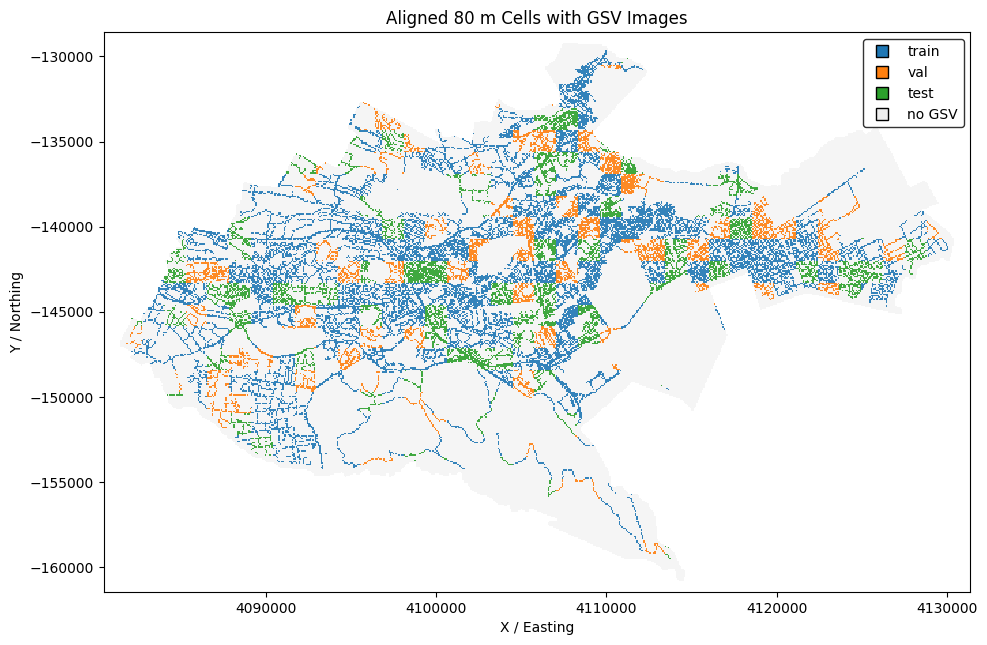

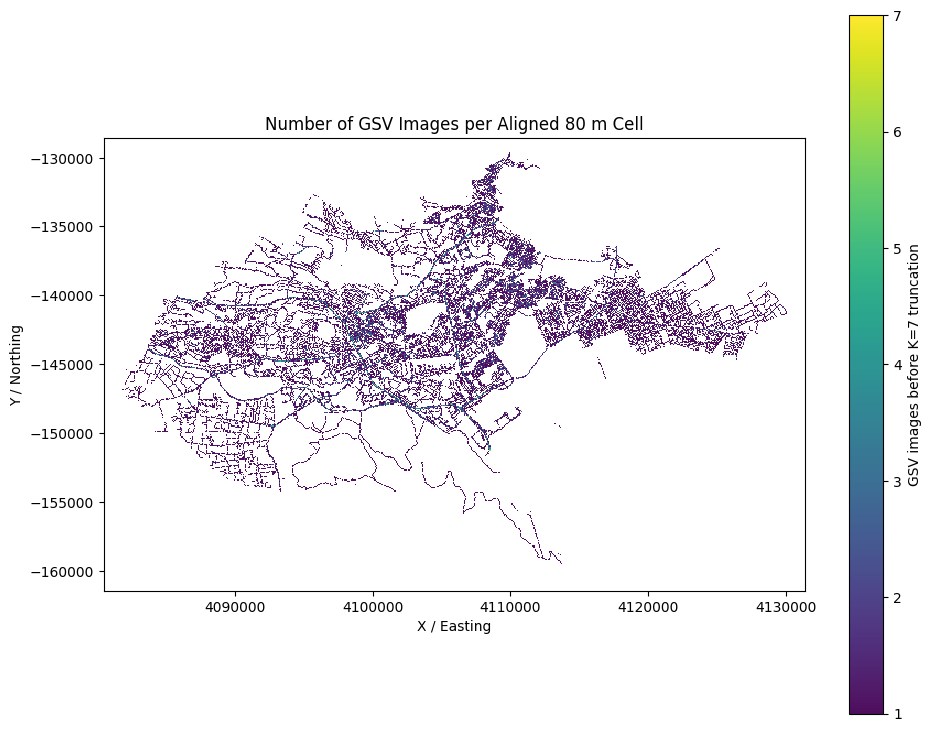

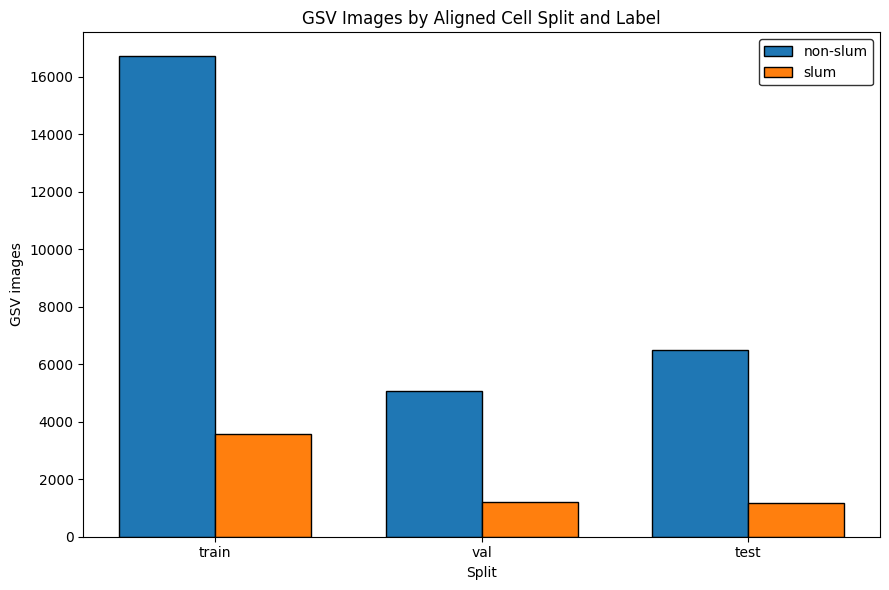

,figure_name,path,exists
0,full_gsv_available_cells_map,F:\Master Research Thesis\Code\Mapping_Generat...,True
1,full_gsv_image_count_per_cell_map,F:\Master Research Thesis\Code\Mapping_Generat...,True
2,full_gsv_image_counts_by_split_and_label,F:\Master Research Thesis\Code\Mapping_Generat...,True


In [12]:
# =========================
# 11. QUALITY-CONTROL FIGURES
# =========================

def rectangles_from_df(dataframe):
    return [
        Rectangle(
            (float(row.xmin), float(row.ymin)),
            float(row.xmax - row.xmin),
            float(row.ymax - row.ymin),
        )
        for row in dataframe.itertuples(index=False)
    ]


def setup_map_axis(axis, dataframe, title):
    xmin = float(dataframe["xmin"].min())
    xmax = float(dataframe["xmax"].max())
    ymin = float(dataframe["ymin"].min())
    ymax = float(dataframe["ymax"].max())

    pad_x = (xmax - xmin) * 0.02
    pad_y = (ymax - ymin) * 0.02

    axis.set_xlim(xmin - pad_x, xmax + pad_x)
    axis.set_ylim(ymin - pad_y, ymax + pad_y)
    axis.set_aspect("equal")
    axis.set_title(title)
    axis.set_xlabel("X / Easting")
    axis.set_ylabel("Y / Northing")
    axis.grid(False)
    axis.set_facecolor("white")
    axis.figure.set_facecolor("white")
    axis.ticklabel_format(style="plain", useOffset=False, axis="both")


mapped_cell_counts = (
    mapped_df
    .groupby(["final_split", "row_index_in_split"])
    .size()
    .rename("gsv_image_count")
    .reset_index()
)

gsv_count_per_cell_df = cell_df.loc[cell_df["valid_cell"]].merge(
    mapped_cell_counts,
    left_on=["split", "row_index_in_split"],
    right_on=["final_split", "row_index_in_split"],
    how="left",
    validate="one_to_one",
)

gsv_count_per_cell_df["gsv_image_count"] = (
    gsv_count_per_cell_df["gsv_image_count"]
    .fillna(0)
    .astype(int)
)

gsv_count_per_cell_df["has_gsv"] = (
    gsv_count_per_cell_df["gsv_image_count"] > 0
)

# Figure 1: availability.
fig, ax = plt.subplots(figsize=(10, 10), facecolor="white")

ax.add_collection(
    PatchCollection(
        rectangles_from_df(gsv_count_per_cell_df),
        facecolor="#eeeeee",
        edgecolor="black",
        linewidths=CELL_EDGE_WIDTH,
        alpha=0.55,
        antialiased=False,
    )
)

for split in ["train", "val", "test"]:
    group = gsv_count_per_cell_df[
        (gsv_count_per_cell_df["split"] == split)
        & (gsv_count_per_cell_df["has_gsv"])
    ]

    ax.add_collection(
        PatchCollection(
            rectangles_from_df(group),
            facecolor=SPLIT_COLORS[split],
            edgecolor="black",
            linewidths=CELL_EDGE_WIDTH,
            alpha=0.90,
            antialiased=False,
        )
    )

setup_map_axis(
    ax,
    gsv_count_per_cell_df,
    "Aligned 80 m Cells with GSV Images",
)

handles = [
    Line2D(
        [0], [0],
        marker="s",
        linestyle="None",
        markerfacecolor=SPLIT_COLORS[split],
        markeredgecolor="black",
        markersize=9,
        label=split,
    )
    for split in ["train", "val", "test"]
]

handles.append(
    Line2D(
        [0], [0],
        marker="s",
        linestyle="None",
        markerfacecolor="#eeeeee",
        markeredgecolor="black",
        markersize=9,
        label="no GSV",
    )
)

ax.legend(
    handles=handles,
    loc="best",
    frameon=True,
    facecolor="white",
    edgecolor="black",
)

availability_figure = FIG_DIR / "full_gsv_aligned_v2_available_cells_map.png"
plt.tight_layout()
fig.savefig(
    availability_figure,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()
plt.close(fig)

# Figure 2: count per cell.
fig, ax = plt.subplots(figsize=(10, 10), facecolor="white")

covered_cells = gsv_count_per_cell_df[
    gsv_count_per_cell_df["gsv_image_count"] > 0
].copy()

count_collection = PatchCollection(
    rectangles_from_df(covered_cells),
    array=covered_cells["gsv_image_count"].to_numpy(),
    cmap="viridis",
    edgecolor="black",
    linewidths=CELL_EDGE_WIDTH,
    alpha=0.95,
    antialiased=False,
)

ax.add_collection(count_collection)

setup_map_axis(
    ax,
    gsv_count_per_cell_df,
    "Number of GSV Images per Aligned 80 m Cell",
)

colorbar = fig.colorbar(count_collection, ax=ax, shrink=0.72)
colorbar.set_label("GSV images before K=7 truncation")

count_figure = FIG_DIR / "full_gsv_aligned_v2_image_count_per_cell_map.png"
plt.tight_layout()
fig.savefig(
    count_figure,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()
plt.close(fig)

# Figure 3: image counts by split and label.
bar_df = image_count_long[
    image_count_long["final_split"].isin(["train", "val", "test"])
].copy()

x_positions = np.arange(3)
bar_width = 0.36

non_slum_values = [
    int(
        bar_df[
            (bar_df["final_split"] == split)
            & (bar_df["final_label"] == "non_slum")
        ]["images"].sum()
    )
    for split in ["train", "val", "test"]
]

slum_values = [
    int(
        bar_df[
            (bar_df["final_split"] == split)
            & (bar_df["final_label"] == "slum")
        ]["images"].sum()
    )
    for split in ["train", "val", "test"]
]

fig, ax = plt.subplots(figsize=(9, 6), facecolor="white")

ax.bar(
    x_positions - bar_width / 2,
    non_slum_values,
    bar_width,
    label="non-slum",
    edgecolor="black",
)

ax.bar(
    x_positions + bar_width / 2,
    slum_values,
    bar_width,
    label="slum",
    edgecolor="black",
)

ax.set_xticks(x_positions)
ax.set_xticklabels(["train", "val", "test"])
ax.set_xlabel("Split")
ax.set_ylabel("GSV images")
ax.set_title("GSV Images by Aligned Cell Split and Label")
ax.grid(False)
ax.legend(frameon=True, facecolor="white", edgecolor="black")

bar_figure = (
    FIG_DIR
    / "full_gsv_aligned_v2_image_counts_by_split_and_label.png"
)

plt.tight_layout()
fig.savefig(
    bar_figure,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()
plt.close(fig)

figure_manifest = pd.DataFrame([
    {
        "figure_name": "full_gsv_available_cells_map",
        "path": str(availability_figure),
        "exists": availability_figure.exists(),
    },
    {
        "figure_name": "full_gsv_image_count_per_cell_map",
        "path": str(count_figure),
        "exists": count_figure.exists(),
    },
    {
        "figure_name": "full_gsv_image_counts_by_split_and_label",
        "path": str(bar_figure),
        "exists": bar_figure.exists(),
    },
])

figure_manifest.to_csv(
    OUT_DIR / "full_gsv_figure_manifest_v2.csv",
    index=False,
)

display(figure_manifest)

## Module 12 — Consolidated aligned-v2 audit

The report combines source counts, mapping outcomes, cell-level and image-level
validation, out reasons, duplicates, target collisions, and K=7 overflow.

In [13]:
# =========================
# 12. CONSOLIDATED ALIGNED-V2 AUDIT
# =========================

out_images_df = full_gsv_df[
    ~full_gsv_df["mapping_ok"]
].copy()

out_images_df.to_csv(
    OUT_DIR / "full_gsv_out_images_v2.csv",
    index=False,
)

out_reason_summary.to_csv(
    OUT_DIR / "full_gsv_out_reason_summary_v2.csv",
    index=False,
)

audit_warnings = []

if len(duplicate_filename_df) > 0:
    audit_warnings.append(
        f"Duplicate filename rows: {len(duplicate_filename_df)}."
    )

if len(duplicate_fid_df) > 0:
    audit_warnings.append(
        f"Duplicate FID rows: {len(duplicate_fid_df)}."
    )

if len(duplicate_coordinate_df) > 0:
    audit_warnings.append(
        f"Duplicate coordinate rows: {len(duplicate_coordinate_df)}."
    )

if images_beyond_k7 > 0:
    audit_warnings.append(
        f"Images beyond K=7: {images_beyond_k7}."
    )

blocking_issues = []

if len(cell_raster_mismatch_df) > 0:
    blocking_issues.append(
        f"Cell-to-raster mismatches: {len(cell_raster_mismatch_df)}."
    )

if len(label_mismatch_df) > 0:
    blocking_issues.append(
        f"Image-to-cell validation issues: {len(label_mismatch_df)}."
    )

if len(global_cell_issue_df) > 0:
    blocking_issues.append(
        f"Global-cell consistency issues: {len(global_cell_issue_df)}."
    )

if len(duplicate_source_path_df) > 0:
    blocking_issues.append(
        f"Duplicate source-path rows: {len(duplicate_source_path_df)}."
    )

if len(target_collision_df) > 0:
    blocking_issues.append(
        f"Target-path collision rows: {len(target_collision_df)}."
    )

audit_lines = [
    "=" * 96,
    "Complete GSV Reclassification Audit — Aligned v2",
    f"RUN_ID: {RUN_ID}",
    f"OUT_DIR: {OUT_DIR}",
    "=" * 96,
    "",
    "[Authoritative Sources]",
    f"Patch mapping: {PATCH_MAPPING_FILE}",
    f"Cell mapping: {CELL_MAPPING_FILE}",
    f"Aligned reference: {LABEL_RASTER_FILE}",
    "",
    "[Input]",
    f"Source folder: {FULL_GSV_SOURCE_DIR}",
    f"Image-like files found: {len(all_image_like_files)}",
    f"Real images retained: {len(real_image_paths)}",
    f"Hidden/metadata files ignored: {len(ignored_df)}",
    "",
    "[Cell Mapping]",
    f"Selected patches: {len(patch_df)}",
    f"All model positions: {len(cell_df)}",
    f"Valid labelled cells: {int(cell_df['valid_cell'].sum())}",
    f"Invalid/background/padding positions: {int((~cell_df['valid_cell']).sum())}",
    f"Cell-to-raster mismatches: {len(cell_raster_mismatch_df)}",
    "",
    "[Image Mapping]",
    f"Successfully parsed: {int(full_gsv_df['parse_ok'].sum())}",
    f"Mapped to valid cells: {int(full_gsv_df['mapping_ok'].sum())}",
    f"Assigned to out: {int((~full_gsv_df['mapping_ok']).sum())}",
    f"Image-to-cell validation issues: {len(label_mismatch_df)}",
    f"Global-cell consistency issues: {len(global_cell_issue_df)}",
    "",
    "[Image Counts]",
    image_count_table.to_string(),
    "",
    "[Unique Cells with GSV]",
    cell_coverage_table.to_string(),
    "",
    "[Out Reasons]",
    out_reason_summary.to_string(index=False),
    "",
    "[Duplicate and Collision Audit]",
    f"Duplicate filename rows: {len(duplicate_filename_df)}",
    f"Duplicate FID rows: {len(duplicate_fid_df)}",
    f"Duplicate coordinate rows: {len(duplicate_coordinate_df)}",
    f"Duplicate source-path rows: {len(duplicate_source_path_df)}",
    f"Target-path collision rows: {len(target_collision_df)}",
    "",
    "[K=7 Slot Audit]",
    f"Maximum images in one cell: {maximum_images_per_cell}",
    f"Images beyond K=7: {images_beyond_k7}",
    f"All-position wide rows: {len(slot_paths_all_positions)}",
    f"Valid-cell wide rows: {len(slot_paths_valid_cells)}",
    "",
    "[Warnings]",
]

if audit_warnings:
    audit_lines.extend(audit_warnings)
else:
    audit_lines.append("No non-blocking warnings.")

audit_lines.extend(["", "[Blocking Issues]"])

if blocking_issues:
    audit_lines.extend(blocking_issues)
else:
    audit_lines.append("No blocking issues were detected.")

audit_text = "\n".join(audit_lines)

audit_file = (
    OUT_DIR / "full_gsv_reclassification_audit_v2.txt"
)

with open(audit_file, "w", encoding="utf-8") as file:
    file.write(audit_text)

print(audit_text)
print("")
print("Saved:", audit_file)

if blocking_issues:
    raise RuntimeError(
        "Blocking issues remain. Review the audit before copying."
    )

Complete GSV Reclassification Audit — Aligned v2
RUN_ID: 20260730_145747
OUT_DIR: F:\Master Research Thesis\Code\Mapping_Generation\outputs\full_gsv_aligned_v2_run_20260730_145747

[Authoritative Sources]
Patch mapping: F:\Master Research Thesis\Code\Mapping_Generation\outputs\latest_aligned_v2\patch_index_mapping.csv
Cell mapping: F:\Master Research Thesis\Code\Mapping_Generation\outputs\latest_aligned_v2\cell_index_mapping_v2.csv
Aligned reference: F:\Master Research Thesis\Code\Mapping_Generation\reference_alignment_v2\Nrb_reference_binary_aligned_to_s2_80m.tif

[Input]
Source folder: H:\Research Thesis\Dataset\Nrb_GSV\Nrb_images
Image-like files found: 69174
Real images retained: 34587
Hidden/metadata files ignored: 34587

[Cell Mapping]
Selected patches: 510
All model positions: 130560
Valid labelled cells: 112600
Invalid/background/padding positions: 17960
Cell-to-raster mismatches: 0

[Image Mapping]
Successfully parsed: 34587
Mapped to valid cells: 34207
Assigned to out: 380
Im

## Module 13 — Build and validate the copy plan

The copy plan uses the aligned-v2 manifest. Expected counts are derived from the
classification result, not hard-coded. Copying is blocked by missing source files,
duplicate source paths, or target collisions.

In [14]:
# =========================
# 13. BUILD AND VALIDATE THE COPY PLAN
# =========================

copy_plan_df = full_gsv_df.copy()

allowed_combinations = {
    ("train", "non_slum"),
    ("train", "slum"),
    ("val", "non_slum"),
    ("val", "slum"),
    ("test", "non_slum"),
    ("test", "slum"),
    ("out", "out"),
}

actual_combinations = set(
    zip(
        copy_plan_df["final_split"],
        copy_plan_df["final_label"],
    )
)

unexpected_combinations = actual_combinations - allowed_combinations

if unexpected_combinations:
    raise ValueError(
        "Unexpected split/label combinations:\n"
        f"{sorted(unexpected_combinations)}"
    )

copy_plan_df["source_exists"] = (
    copy_plan_df["image_path_absolute"]
    .map(lambda value: Path(value).exists())
)

missing_source_df = copy_plan_df[
    copy_plan_df["source_exists"] != True
].copy()

missing_source_df.to_csv(
    OUT_DIR / "full_gsv_missing_source_files_v2.csv",
    index=False,
)

if len(missing_source_df) > 0:
    raise FileNotFoundError(
        f"{len(missing_source_df)} source images are missing."
    )

if copy_plan_df["filename"].astype(str).str.startswith("._").any():
    raise ValueError("AppleDouble files remain in the copy plan.")

if len(duplicate_source_path_df) > 0:
    raise ValueError(
        "Duplicate source paths must be resolved before copying."
    )

if len(target_collision_df) > 0:
    raise ValueError(
        "Target-path collisions must be resolved before copying."
    )

copy_plan_df["target_path_absolute"] = (
    copy_plan_df["target_relative_path"]
    .map(lambda value: str(TARGET_ROOT / Path(value)))
)

expected_counts = (
    copy_plan_df
    .groupby(["final_split", "final_label"])
    .size()
    .rename("expected_images")
    .reset_index()
)

expected_total = len(copy_plan_df)

copy_plan_file = (
    OUT_DIR
    / "full_gsv_verified_dataset_copy_plan_v2.csv"
)

copy_plan_df.to_csv(copy_plan_file, index=False)

expected_counts.to_csv(
    OUT_DIR / "full_gsv_expected_copy_counts_v2.csv",
    index=False,
)

print("=" * 88)
print("COPY PLAN")
print("=" * 88)
display(expected_counts)

print("Expected total:", expected_total)
print("DRY_RUN:", DRY_RUN)
print("Target root:", TARGET_ROOT)
print("Saved copy plan:", copy_plan_file)

COPY PLAN


,final_split,final_label,expected_images
0,out,out,380
1,test,non_slum,6510
2,test,slum,1165
3,train,non_slum,16713
4,train,slum,3569
5,val,non_slum,5055
6,val,slum,1195


Expected total: 34587
DRY_RUN: True
Target root: H:\Research Thesis\Dataset\Nrb_GSV\Nrb_images_verified_by_aligned_cell_v2
Saved copy plan: F:\Master Research Thesis\Code\Mapping_Generation\outputs\full_gsv_aligned_v2_run_20260730_145747\full_gsv_verified_dataset_copy_plan_v2.csv


## Module 14 — Optional physical dataset creation

With `DRY_RUN = True`, no images are copied. After reviewing the audits, change it to `False` in Module 2 and run the notebook from the beginning. Images are copied with metadata-preserving `shutil.copy2`, checked by file size, and counted again in the target folders.

In [15]:
# =========================
# 14. CREATE VERIFIED PHYSICAL DATASET
# =========================

METADATA_DIR = TARGET_ROOT / "_metadata"

if DRY_RUN:
    print("DRY_RUN = True")
    print("No images were copied.")
    print("")
    print(
        "After reviewing every audit result, change DRY_RUN to False "
        "in Module 2 and run all cells again."
    )

else:
    if TARGET_ROOT.exists():
        existing_files = [
            path
            for path in TARGET_ROOT.rglob("*")
            if path.is_file()
        ]

        if existing_files and not ALLOW_NONEMPTY_TARGET:
            raise FileExistsError(
                f"{TARGET_ROOT} already contains "
                f"{len(existing_files)} files. "
                "Use a new versioned folder or remove the incomplete "
                "target after checking it."
            )

    target_directories = [
        TARGET_ROOT / "train" / "non_slum",
        TARGET_ROOT / "train" / "slum",
        TARGET_ROOT / "val" / "non_slum",
        TARGET_ROOT / "val" / "slum",
        TARGET_ROOT / "test" / "non_slum",
        TARGET_ROOT / "test" / "slum",
        TARGET_ROOT / "out",
        METADATA_DIR,
    ]

    for directory in target_directories:
        directory.mkdir(parents=True, exist_ok=True)

    copy_records = []

    for copy_number, row in enumerate(
        copy_plan_df.itertuples(index=False),
        start=1,
    ):
        source = Path(row.image_path_absolute)
        target = Path(row.target_path_absolute)

        target.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(source, target)

        source_size = source.stat().st_size
        target_size = target.stat().st_size
        size_match = source_size == target_size

        if not size_match:
            raise IOError(
                "Copied file size does not match source:\n"
                f"Source: {source}\n"
                f"Target: {target}"
            )

        copy_records.append({
            "source_path": str(source),
            "target_path": str(target),
            "target_relative_path": row.target_relative_path,
            "final_split": row.final_split,
            "final_label": row.final_label,
            "filename": row.filename,
            "source_size_bytes": source_size,
            "target_size_bytes": target_size,
            "size_match": size_match,
            "copy_status": "copied",
        })

        if copy_number % 1000 == 0 or copy_number == expected_total:
            print(
                f"Copied {copy_number:,} / "
                f"{expected_total:,} images"
            )

    copy_log_df = pd.DataFrame(copy_records)

    copy_log_df.to_csv(
        METADATA_DIR / "full_gsv_verified_copy_log_v2.csv",
        index=False,
    )

    verification_rows = []

    for row in expected_counts.itertuples(index=False):
        split_value = row.final_split
        label_value = row.final_label
        expected_count = int(row.expected_images)

        if split_value == "out":
            folder = TARGET_ROOT / "out"
        else:
            folder = (
                TARGET_ROOT
                / split_value
                / label_value
            )

        actual_files = [
            path
            for path in folder.rglob("*")
            if is_real_image(path)
        ]

        actual_count = len(actual_files)

        verification_rows.append({
            "split": split_value,
            "label": label_value,
            "expected_images": expected_count,
            "actual_images": actual_count,
            "difference": actual_count - expected_count,
            "matches_expected": actual_count == expected_count,
        })

    physical_verification_df = pd.DataFrame(verification_rows)

    physical_verification_df.to_csv(
        METADATA_DIR / "full_gsv_verified_dataset_summary_v2.csv",
        index=False,
    )

    display(physical_verification_df)

    if not physical_verification_df["matches_expected"].all():
        raise RuntimeError(
            "Physical folder counts do not match the manifest."
        )

    actual_total = int(
        physical_verification_df["actual_images"].sum()
    )

    if actual_total != expected_total:
        raise RuntimeError(
            f"Physical total {actual_total} does not match "
            f"expected total {expected_total}."
        )

    metadata_files = [
        PATCH_MAPPING_FILE,
        CELL_MAPPING_FILE,
        OUT_DIR / "full_gsv_reclassification_config_v2.json",
        OUT_DIR / "full_gsv_source_inventory_v2.csv",
        OUT_DIR / "full_gsv_manifest_aligned_v2.csv",
        OUT_DIR / "full_gsv_image_counts_table_v2.csv",
        OUT_DIR / "full_gsv_cell_coverage_table_v2.csv",
        OUT_DIR / "full_gsv_cell_slot_mapping_v2.csv",
        OUT_DIR / "full_gsv_slot_paths_wide_k7_all_model_positions_v2.csv",
        OUT_DIR / "full_gsv_slot_paths_wide_k7_valid_cells_v2.csv",
        OUT_DIR / "full_gsv_image_to_cell_validation_issues_v2.csv",
        OUT_DIR / "full_gsv_out_images_v2.csv",
        OUT_DIR / "full_gsv_target_path_collisions_v2.csv",
        OUT_DIR / "full_gsv_reclassification_audit_v2.txt",
        OUT_DIR / "full_gsv_verified_dataset_copy_plan_v2.csv",
    ]

    for source_file in metadata_files:
        source_file = Path(source_file)

        if source_file.exists():
            shutil.copy2(
                source_file,
                METADATA_DIR / source_file.name,
            )

    if FIG_DIR.exists():
        target_figure_dir = METADATA_DIR / "figures"

        if target_figure_dir.exists():
            shutil.rmtree(target_figure_dir)

        shutil.copytree(FIG_DIR, target_figure_dir)

    dataset_description = {
        "dataset_name": TARGET_ROOT.name,
        "source_folder": str(FULL_GSV_SOURCE_DIR),
        "target_folder": str(TARGET_ROOT),
        "total_images": expected_total,
        "authoritative_split_source": "cell_index_mapping_v2.csv",
        "authoritative_label_source": "cell_index_mapping_v2.csv",
        "aligned_reference_validation_source": str(LABEL_RASTER_FILE),
        "label_0": "non_slum",
        "label_1": "slum",
        "out_included_in_model": False,
        "original_source_modified": False,
        "copy_method": "shutil.copy2",
        "K": K,
        "slot_order": (
            "numeric FID where possible, then filename and source path"
        ),
        "run_id": RUN_ID,
    }

    with open(
        METADATA_DIR / "dataset_description_v2.json",
        "w",
        encoding="utf-8",
    ) as file:
        json.dump(
            dataset_description,
            file,
            indent=2,
            ensure_ascii=False,
        )

    print("Verified GSV dataset created successfully:")
    print(TARGET_ROOT)
    print("Metadata archived to:")
    print(METADATA_DIR)

DRY_RUN = True
No images were copied.

After reviewing every audit result, change DRY_RUN to False in Module 2 and run all cells again.


## Module 15 — Reproducibility manifest and stable latest output

The final module records package versions and SHA-256 hashes for the authoritative
mapping/configuration files, then copies the complete timestamped result to:

```text
F:\Master Research Thesis\Code\Mapping_Generation\outputs\
latest_full_gsv_aligned_v2
```

In [16]:
# =========================
# 15. REPRODUCIBILITY AND STABLE LATEST OUTPUT
# =========================

def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()

    with open(path, "rb") as file:
        while True:
            chunk = file.read(chunk_size)

            if not chunk:
                break

            digest.update(chunk)

    return digest.hexdigest()


small_reference_files = [
    PATCH_MAPPING_FILE,
    CELL_MAPPING_FILE,
    LABEL_RASTER_FILE,
    OUT_DIR / "full_gsv_reclassification_config_v2.json",
    OUT_DIR / "full_gsv_reclassification_audit_v2.txt",
]

reference_rows = []

for path in small_reference_files:
    path = Path(path)

    if path.exists():
        stat = path.stat()

        reference_rows.append({
            "path": str(path),
            "size_bytes": stat.st_size,
            "modified_timestamp": stat.st_mtime,
            "sha256": sha256_file(path),
        })

reference_manifest_df = pd.DataFrame(reference_rows)

reference_manifest_df.to_csv(
    OUT_DIR / "reference_file_hash_manifest_v2.csv",
    index=False,
)

environment_manifest = {
    "python_version": sys.version,
    "platform": platform.platform(),
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "matplotlib_version": plt.matplotlib.__version__,
    "rasterio_version": rasterio.__version__,
    "coordinate_transform": "EPSG:4326 -> EPSG:3857",
    "run_id": RUN_ID,
    "out_dir": str(OUT_DIR),
}

with open(
    OUT_DIR / "environment_manifest_v2.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        environment_manifest,
        file,
        indent=2,
        ensure_ascii=False,
    )

if LATEST_GSV_DIR.exists():
    shutil.rmtree(LATEST_GSV_DIR)

shutil.copytree(OUT_DIR, LATEST_GSV_DIR)

latest_pointer = {
    "run_id": RUN_ID,
    "timestamped_run": str(OUT_DIR),
    "stable_latest": str(LATEST_GSV_DIR),
    "manifest": str(
        LATEST_GSV_DIR / "full_gsv_manifest_aligned_v2.csv"
    ),
    "all_model_positions_slot_table": str(
        LATEST_GSV_DIR
        / "full_gsv_slot_paths_wide_k7_all_model_positions_v2.csv"
    ),
    "valid_cells_slot_table": str(
        LATEST_GSV_DIR
        / "full_gsv_slot_paths_wide_k7_valid_cells_v2.csv"
    ),
}

with open(
    LATEST_GSV_DIR / "latest_run_pointer_v2.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        latest_pointer,
        file,
        indent=2,
        ensure_ascii=False,
    )

print("Saved reproducibility manifests.")
display(reference_manifest_df)

print("Timestamped output folder:")
print(OUT_DIR)

print("Stable latest output folder:")
print(LATEST_GSV_DIR)

Saved reproducibility manifests.


,path,size_bytes,modified_timestamp,sha256
0,F:\Master Research Thesis\Code\Mapping_Generat...,30209,1.785413e+09,8a6f17771aec0468d5415b47b8a48da4030bcfb12019dd...
1,F:\Master Research Thesis\Code\Mapping_Generat...,13556357,1.785413e+09,648277a5322ccb7009d51dcd277f1fa4045e34c54cd080...
2,F:\Master Research Thesis\Code\Mapping_Generat...,6446,1.785341e+09,1a2e2ebba4b5753a30753711a88146fdeea3c854d5af2e...
3,F:\Master Research Thesis\Code\Mapping_Generat...,1106,1.785420e+09,3e505db3b6067e671d0488476fbeccbb2a81c410f1d4c1...
4,F:\Master Research Thesis\Code\Mapping_Generat...,2419,1.785428e+09,0d603bdcdd3277e4e201682489e156f4c3953f74d422c2...


Timestamped output folder:
F:\Master Research Thesis\Code\Mapping_Generation\outputs\full_gsv_aligned_v2_run_20260730_145747
Stable latest output folder:
F:\Master Research Thesis\Code\Mapping_Generation\outputs\latest_full_gsv_aligned_v2


# Review checklist before setting `DRY_RUN = False`

Confirm:

1. `Cell-to-raster mismatches = 0`.
2. `Image-to-cell validation issues = 0`.
3. `Global-cell consistency issues = 0`.
4. Every out image has a clear `mapping_status`.
5. Duplicate source paths and target-path collisions are both zero.
6. Image counts by split and inherited cell label are plausible.
7. Unique GSV-covered cell counts are plausible.
8. K=7 overflow has been reviewed.
9. The all-position wide table contains exactly 130,560 rows.
10. The valid-cell wide table contains exactly the number of `valid_cell=True` rows in `cell_index_mapping_v2.csv`.
11. QA figures show sensible spatial coverage.
12. `TARGET_ROOT` is the intended new versioned folder.

The principal outputs for the next feature-extraction stage are:

```text
latest_full_gsv_aligned_v2\full_gsv_manifest_aligned_v2.csv

latest_full_gsv_aligned_v2\full_gsv_cell_slot_mapping_v2.csv

latest_full_gsv_aligned_v2\
full_gsv_slot_paths_wide_k7_all_model_positions_v2.csv
```

Physical copying is optional. Feature extraction can read the original image paths
directly from the manifest and slot tables.